# TuniShop — 06. EDA Marketing et finance : paiements, campagnes, coupons, remboursements

**Auteure :** Sarra Abdeljaouad · **Source :** TuniShop_DWH, lecture directe des vues `bi` (SQL Server) · **Période :** 01/01/2023 – 31/12/2025

**Objectif :** évaluer la rentabilité du marketing, l'effet des coupons, et les flux financiers sortants (échecs de paiement, remboursements).

| N° (Plan_Analyse_EDA) | Question |
|---|---|
| Q10 | Pourquoi les paiements échouent-ils ? Une 2e tentative réussit-elle ? |
| Q11 | Quelles campagnes rapportent le plus par dinar dépensé ? |
| Q12 | Les coupons augmentent-ils le panier ? À qui servent-ils ? |
| Q17 | Pourquoi les clients demandent-ils un remboursement ? Qui en est responsable ? |

Pour chaque question : un tableau rappelle l'**hypothèse** du plan d'analyse, les **vues** utilisées et la **méthode** ; puis viennent le calcul (cellules **🔗 SQL direct** exécutées par SQL Server, et pandas), le graphique, la **lecture** et le **verdict** de l'hypothèse (✅ confirmée, 🟡 nuancée, ❌ infirmée).

Les figures sont enregistrées dans `06_Exports/Figures` et les tableaux de résultats dans `06_Exports/Tables` : ils alimentent les rapports de `04_Livrables/EDA`.

## 0. Connexion au DWH et chargement

Le notebook lit les 23 vues `bi.v_*` **en direct** dans SQL Server (réglages dans `00_Commun/tunishop_analytics/config.py`), puis vérifie qu'il s'agit bien du DWH validé.

In [1]:
# --- Bibliothèques
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# --- Module commun du projet (dossier 00_Commun, à côté de ce dossier)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, validation, features, temporal_split, publication

warnings.filterwarnings("ignore", category=FutureWarning)      # messages de version sans intérêt ici
cfg.appliquer_style()

# --- Raccourcis
sql = chargement.requete                                       # sql("SELECT ...") -> exécuté par SQL Server

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

In [2]:
chargement.ouvrir_connexion()
vues, p = chargement.charger_donnees(source="dwh")

# Raccourcis vers les tables préparées
cmd, lig, liv, avis, rmb, pai = p["cmd"], p["lig"], p["liv"], p["avis"], p["rmb"], p["pai"]

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)
Lecture directe des vues bi.v_* — 13/11/2026 23:43
  v_dim_date                        1 828 lignes


  v_dim_client                     16 002 lignes
  v_dim_produit                     1 603 lignes
  v_dim_fournisseur                    42 lignes
  v_dim_geographie                     26 lignes
  v_dim_entrepot                        5 lignes
  v_dim_transporteur                    6 lignes
  v_dim_campagne                      154 lignes
  v_dim_coupon                         70 lignes
  v_dim_canal                           8 lignes
  v_dim_mode_paiement                   7 lignes
  v_dim_statut_commande                10 lignes
  v_dim_motif_retour                   14 lignes


  v_fact_ventes                   115 903 lignes


  v_fact_commandes                 66 268 lignes


  v_fact_paiements                 64 491 lignes


  v_fact_livraisons                61 793 lignes
  v_fact_remboursements             8 815 lignes
  v_fact_avis                       9 314 lignes


  v_fact_marketing_quotidien        3 427 lignes
  v_fact_achats_fournisseur        11 793 lignes


  v_fact_mouvements_stock         140 184 lignes


  v_fact_stock_mensuel             56 562 lignes


In [3]:
# Point de départ contrôlé : 5 totaux, valeur validée (PV) = calcul SQL = calcul Python ? (attendu : OK partout)
validation.verifier_coherence(p)

,controle,indicateur,valide_pv,sql_vues_bi,python_pandas,statut
0,C03,Lignes de vente,115 903.000,115 903.000,115 903.000,OK
1,C04,Commandes,66 268.000,66 268.000,66 268.000,OK
2,C05,Livraisons,61 793.000,61 793.000,61 793.000,OK
3,C06,CA reconnu TTC (DT),15 541 665.655,15 541 665.655,15 541 665.655,OK
4,C07,Clients ayant commandé (hors membre inconnu),12 472.000,12 472.000,12 472.000,OK


### Q10. Pourquoi les paiements échouent-ils ? Une 2e tentative réussit-elle ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | Les échecs ont des causes identifiables ; une nouvelle tentative réussit souvent ; le reversement dépend du transporteur. |
| **Indicateurs** | Échecs par code d'erreur, taux de réussite par tentative, délai de reversement |
| **Vues bi utilisées** | `v_fact_paiements`, `v_dim_mode_paiement` |
| **Méthode** | SQL direct + pandas |
| **Visualisation** | Tableaux ; barres des délais |
| **Lien data mining / ML** | Contexte (pas de cas ML direct) |

In [4]:
# 🔗 SQL direct — causes d'échec (code d'erreur) des paiements en ligne
causes = sql("""
    SELECT p.code_erreur,
           COUNT(*)              AS echecs,
           SUM(p.montant_ttc)    AS montant_ttc
    FROM bi.v_fact_paiements p
    WHERE p.est_reussi = 0
    GROUP BY p.code_erreur
    ORDER BY echecs DESC
""")
causes["part"] = causes["echecs"] / causes["echecs"].sum()
display(causes)

# 🔗 SQL direct — taux de réussite selon le numéro de tentative
sql("""
    SELECT p.num_tentative,
           COUNT(*)                                                     AS tentatives,
           1.0 * SUM(CASE WHEN p.est_reussi = 1 THEN 1 ELSE 0 END) / COUNT(*) AS taux_reussite
    FROM bi.v_fact_paiements p
    GROUP BY p.num_tentative
    ORDER BY p.num_tentative
""")

,code_erreur,echecs,montant_ttc,part
0,refus_banque,891,241 239.560,0.207
1,fonds_insuffisants,880,249 941.370,0.205
2,authentification_3ds_echouee,856,219 885.355,0.199
3,carte_expiree,840,230 296.195,0.195
4,delai_depasse,831,220 714.550,0.193


,num_tentative,tentatives,taux_reussite
0,1,61498,0.936
1,2,2741,0.874
2,3,252,0.857


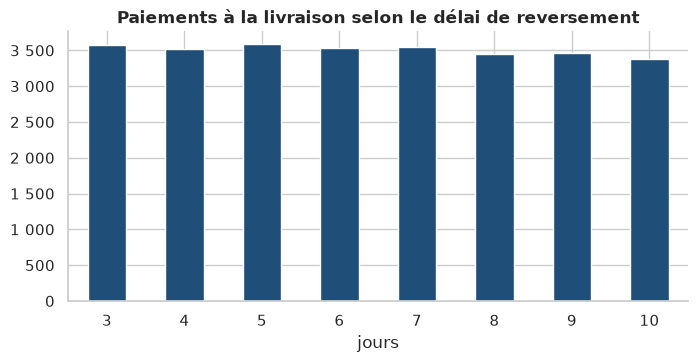

,paiements,delai_moyen_j,delai_max_j
prestataire,,,
Poste Colis Plus,8441,6.477,10.000
Rapid Colis,8058,6.501,10.000
SahelLog,6923,6.387,10.000
TunExpress,4634,6.482,10.000


In [5]:
# Délai de reversement du paiement à la livraison (argent collecté par le transporteur puis reversé)
cod = pai[pai["delai_reversement_j"].notna()]
fig, ax = plt.subplots(figsize=(8, 3.5))
cod["delai_reversement_j"].astype(int).value_counts().sort_index().plot.bar(ax=ax, color=cfg.BLEU, rot=0)
ax.set_title("Paiements à la livraison selon le délai de reversement"); ax.set_xlabel("jours"); cfg.format_milliers(ax)
montrer("Q10_1")
# Le délai dépend-il du transporteur qui collecte l'argent (colonne prestataire) ?
cod.groupby("prestataire")["delai_reversement_j"].agg(paiements="size", delai_moyen_j="mean", delai_max_j="max")

In [6]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(causes, "Q10_causes_echec")
print("Tableaux exportés.")

Publication : connecté à TuniShop_ANALYTICS sur localhost
  ✔ ana.eda_q10_causes_echec                          5 lignes
Tableaux exportés.


> **Lecture.** Les 4 298 paiements échoués se répartissent **à parts presque égales** entre 5 causes (refus bancaire, fonds insuffisants, 3-D Secure, carte expirée, délai dépassé : 19 à 21 % chacune) : aucune cause ne domine, il n'y a donc pas d'action unique à mener. Une 2e tentative réussit dans 87 % des cas (contre 94 % pour la 1re). Le délai de reversement du paiement à la livraison va de 3 à 10 jours (moyenne 6,5) et il est **le même pour tous les transporteurs** : ce n'est pas un levier de négociation.

> 🟡 **Verdict : hypothèse nuancée** — une 2e tentative réussit dans 87 % des cas, mais les échecs n'ont pas de cause dominante et le reversement ne dépend pas du transporteur.

### Q11. Quelles campagnes rapportent le plus par dinar dépensé ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | Écarts forts entre canaux média : emailing le plus rentable (ROAS ≈ 5,9), TikTok le moins (contrôles CC17 et CC18 du dictionnaire des KPI). |
| **Indicateurs** | Dépense HT, CA attribué, ROAS, CTR, CPA, nouveaux clients, part du budget, ROAS par année |
| **Vues bi utilisées** | `v_fact_marketing_quotidien`, `v_dim_campagne`, `v_dim_date` |
| **Méthode** | SQL direct |
| **Visualisation** | Nuage ROAS / part du budget ; carte de chaleur par année |
| **Lien data mining / ML** | Contexte ; variable campagne possible pour le churn |

Définitions du dictionnaire des KPI : **ROAS** = CA attribué TTC / dépense HT ; **CTR** = clics / impressions ; **CPA** = dépense HT / commandes attribuées. L'attribution (quelle commande revient à quelle campagne) est fournie par la source.

In [7]:
# 🔗 SQL direct — performance par canal média (hors campagne inconnue)
canaux_media = sql("""
    SELECT ca.canal_media,
           SUM(m.depense_ht)                                             AS depense_ht,
           SUM(m.ca_attribue_ttc)                                        AS ca_attribue_ttc,
           SUM(m.ca_attribue_ttc) / NULLIF(SUM(m.depense_ht), 0)         AS roas,
           1.0 * SUM(m.clics) / NULLIF(SUM(m.impressions), 0)            AS ctr,
           SUM(m.depense_ht) / NULLIF(SUM(m.commandes_attribuees), 0)    AS cpa_ht,
           SUM(m.nouveaux_clients_attribues)                             AS nouveaux_clients
    FROM bi.v_fact_marketing_quotidien m
    JOIN bi.v_dim_campagne ca ON ca.campagne_sk = m.campagne_sk
    WHERE m.campagne_sk > 0
    GROUP BY ca.canal_media
    ORDER BY roas DESC
""").set_index("canal_media")
canaux_media["part_depense"] = canaux_media["depense_ht"] / canaux_media["depense_ht"].sum()
canaux_media

,depense_ht,ca_attribue_ttc,roas,ctr,cpa_ht,nouveaux_clients,part_depense
canal_media,,,,,,,
emailing,23 859.761,140 155.725,5.874,0.030,43.619,92,0.013
facebook_ads,363 275.317,1 213 140.025,3.339,0.012,79.509,894,0.192
sms,59 831.882,191 175.500,3.195,0.020,80.963,123,0.032
google_ads,276 849.434,850 840.315,3.073,0.035,80.691,653,0.147
instagram_ads,339 178.937,999 538.805,2.947,0.010,91.030,682,0.180
influence,515 878.523,1 078 775.920,2.091,0.006,126.565,762,0.273
tiktok_ads,310 518.484,501 144.490,1.614,0.009,161.141,347,0.164


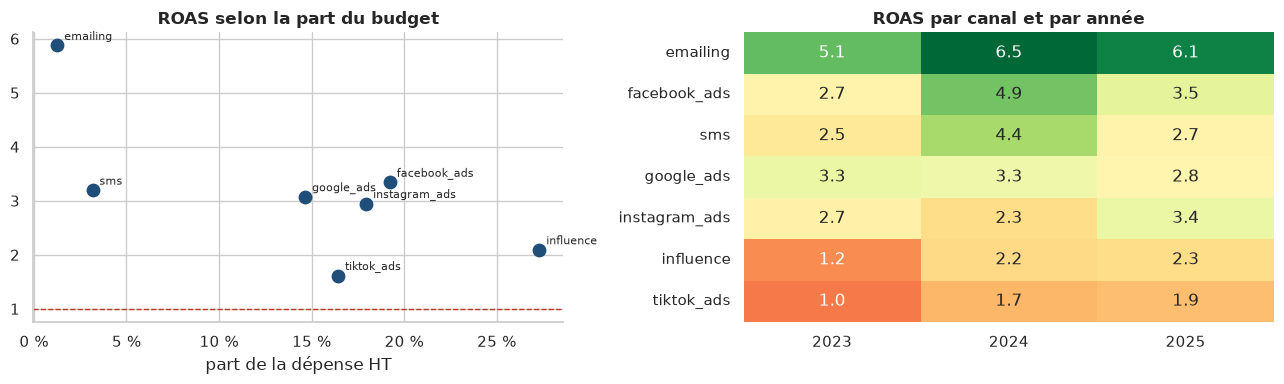

In [8]:
# ROAS par canal média et par année (requête paramétrable : même calcul, ventilé par année)
roas_an = sql("""
    SELECT ca.canal_media, d.annee,
           SUM(m.ca_attribue_ttc) / NULLIF(SUM(m.depense_ht), 0) AS roas
    FROM bi.v_fact_marketing_quotidien m
    JOIN bi.v_dim_campagne ca ON ca.campagne_sk = m.campagne_sk
    JOIN bi.v_dim_date d      ON d.date_sk = m.date_sk
    WHERE m.campagne_sk > 0
    GROUP BY ca.canal_media, d.annee
""").pivot(index="canal_media", columns="annee", values="roas")
roas_an = roas_an.loc[canaux_media.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(canaux_media["part_depense"], canaux_media["roas"], s=80, color=cfg.BLEU)
for nom, r in canaux_media.iterrows():
    axes[0].annotate(nom, (r["part_depense"], r["roas"]), textcoords="offset points", xytext=(5, 4), fontsize=8)
axes[0].axhline(1, color=cfg.ROUGE, lw=1, ls="--")
axes[0].set_title("ROAS selon la part du budget"); axes[0].set_xlabel("part de la dépense HT"); cfg.format_pourcent(axes[0], "x")
sns.heatmap(roas_an, annot=True, fmt=".1f", cmap="RdYlGn", center=3, cbar=False, ax=axes[1])
axes[1].set_title("ROAS par canal et par année"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout(); montrer("Q11_1")

In [9]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(canaux_media, "Q11_performance_canaux_media")
cfg.exporter_table(roas_an, "Q11_roas_annuel")
print("Tableaux exportés.")

  ✔ ana.eda_q11_performance_canaux_media              7 lignes
  ✔ ana.eda_q11_roas_annuel                           7 lignes
Tableaux exportés.


> **Lecture.** L'**emailing** a le meilleur ROAS (5,9 DT de CA pour 1 DT dépensé) mais ne reçoit que **1,3 % du budget** ; l'**influence** reçoit la plus grosse part (27 %) pour un ROAS de 2,1, et **TikTok** a le ROAS le plus faible (1,6) avec le coût par commande le plus élevé (161 DT, contre 44 DT pour l'emailing) : c'est le résultat attendu par le contrôle CC18 du dictionnaire des KPI. Tous les canaux restent rentables (ROAS > 1). TikTok et l'influence progressent chaque année (de 1,0 à 1,9 et de 1,2 à 2,3) ; Facebook a eu un pic en 2024 (4,9). Attention : l'attribution est fournie par les plateformes, elle n'est pas mesurée par TuniShop.

> ✅ **Verdict : hypothèse confirmée** — emailing ROAS 5,9 (le meilleur), TikTok 1,6 (le plus faible), comme le prévoient CC17 et CC18.

### Q12. Les coupons augmentent-ils le panier ? À qui servent-ils ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | Les coupons servent surtout à acquérir de nouveaux clients et sont associés à un panier plus élevé. |
| **Indicateurs** | Part des commandes avec coupon par an et selon 1re commande, panier et articles avec / sans coupon |
| **Vues bi utilisées** | `v_fact_commandes`, `v_dim_coupon`, `v_dim_date` |
| **Méthode** | SQL direct + pandas |
| **Visualisation** | Tableaux |
| **Lien data mining / ML** | Churn : part_coupon |

In [10]:
# 🔗 SQL direct — usage des coupons par année et selon qu'il s'agit d'une première commande
coupons_an = sql("""
    SELECT d.annee,
           COUNT(*)                                                           AS commandes,
           1.0 * SUM(CASE WHEN c.coupon_sk > 0 THEN 1 ELSE 0 END) / COUNT(*)  AS part_avec_coupon,
           SUM(c.remise_coupon_ttc)                                           AS remise_coupon_ttc
    FROM bi.v_fact_commandes c
    JOIN bi.v_dim_date d ON d.date_sk = c.date_commande_sk
    GROUP BY d.annee
    ORDER BY d.annee
""")
coupons_premiere = sql("""
    SELECT CASE WHEN c.est_premiere_commande = 1 THEN 'première commande' ELSE 'commande suivante' END AS commande,
           COUNT(*)                                                           AS commandes,
           1.0 * SUM(CASE WHEN c.coupon_sk > 0 THEN 1 ELSE 0 END) / COUNT(*)  AS part_avec_coupon
    FROM bi.v_fact_commandes c
    GROUP BY CASE WHEN c.est_premiere_commande = 1 THEN 'première commande' ELSE 'commande suivante' END
""")
display(coupons_an); display(coupons_premiere)

# Panier des commandes abouties avec et sans coupon (pandas)
ab = cmd[cmd["est_aboutie"]].assign(avec_coupon=cmd["coupon_sk"] > 0)
ab.groupby("avec_coupon").agg(commandes=("commande_id", "count"), panier_moyen_ttc=("montant_total_ttc", "mean"),
                               articles_moyens=("nb_articles", "mean"), remise_moyenne_ttc=("remise_coupon_ttc", "mean"))

,annee,commandes,part_avec_coupon,remise_coupon_ttc
0,2023,15063,0.103,37 353.675
1,2024,21170,0.073,34 590.325
2,2025,30035,0.085,62 949.960


,commande,commandes,part_avec_coupon
0,première commande,12473,0.292
1,commande suivante,53795,0.037


,commandes,panier_moyen_ttc,articles_moyens,remise_moyenne_ttc
avec_coupon,,,,
False,53852,257.125,2.546,0.000
True,4924,344.228,2.938,23.679


In [11]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(coupons_an, "Q12_coupons_annuels")
print("Tableaux exportés.")

  ✔ ana.eda_q12_coupons_annuels                       3 lignes
Tableaux exportés.


> **Lecture.** Les coupons sont d'abord un **outil d'acquisition** : 29 % des premières commandes en utilisent un, contre 4 % des commandes suivantes. Leur usage a baissé en 2024 (10,3 % → 7,3 % des commandes) avant de remonter en 2025 (8,5 %). Les commandes avec coupon ont un panier plus élevé (344 contre 257 DT, +34 %) et plus d'articles (2,9 contre 2,5), pour une remise moyenne de 24 DT. Prudence : c'est une **association, pas une preuve de cause** (un coupon avec montant minimum attire justement les gros paniers). **Pour le ML :** `part_coupon` est déjà une variable du churn ; il faudra vérifier si les clients acquis par coupon partent plus vite.

> ✅ **Verdict : hypothèse confirmée** — 29 % des premières commandes utilisent un coupon contre 4 % des suivantes ; panier +34 % (association, pas preuve de cause).

### Q17. Pourquoi les clients demandent-ils un remboursement ? Qui en est responsable ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | Une part importante des motifs relève de TuniShop (qualité, préparation, rupture), donc d'actions internes. |
| **Indicateurs** | Demandes, taux de refus, délai moyen, montant remboursé par motif et responsable |
| **Vues bi utilisées** | `v_fact_remboursements`, `v_dim_motif_retour` |
| **Méthode** | SQL direct |
| **Visualisation** | Barres par motif colorées par responsable |
| **Lien data mining / ML** | Churn : nb_demandes_remboursement |

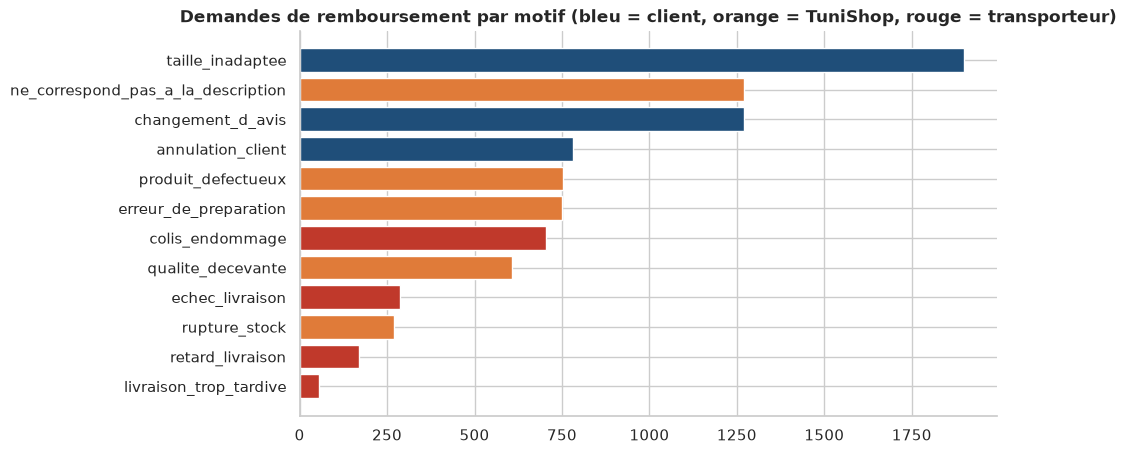

,responsabilite,motif,demandes,taux_refus,delai_moy_j,rembourse_ttc
0,client,taille_inadaptee,1899,0.049,7.540,190 927.947
1,tunishop,ne_correspond_pas_a_la_description,1270,0.078,7.523,173 274.976
2,client,changement_d_avis,1270,0.040,7.436,170 632.927
3,client,annulation_client,781,0.000,2.524,225 138.615
4,tunishop,produit_defectueux,752,0.073,7.446,108 062.438
5,tunishop,erreur_de_preparation,750,0.073,7.511,117 814.463
6,transporteur,colis_endommage,705,0.081,7.478,101 498.699
7,tunishop,qualite_decevante,606,0.086,7.644,53 601.242
8,transporteur,echec_livraison,286,0.000,6.496,77 320.965
9,tunishop,rupture_stock,271,0.000,1.996,273 236.270


,demandes,rembourse_ttc,part_demandes
responsabilite,,,
client,3950,586 699.489,0.448
transporteur,1216,185 624.690,0.138
tunishop,3649,725 989.389,0.414


In [12]:
# 🔗 SQL direct — demandes, refus, délai et montant remboursé par motif et par responsable
motifs = sql("""
    SELECT mr.responsabilite, mr.motif,
           COUNT(*)                                                          AS demandes,
           1.0 * SUM(CASE WHEN r.statut = 'refuse' THEN 1 ELSE 0 END) / COUNT(*) AS taux_refus,
           AVG(1.0 * r.delai_traitement_j)                                    AS delai_moy_j,
           SUM(r.montant_rembourse_ttc)                                       AS rembourse_ttc
    FROM bi.v_fact_remboursements r
    JOIN bi.v_dim_motif_retour mr ON mr.motif_retour_sk = r.motif_retour_sk
    GROUP BY mr.responsabilite, mr.motif
    ORDER BY demandes DESC
""")
couleurs = {"client": cfg.BLEU, "tunishop": cfg.ORANGE, "transporteur": cfg.ROUGE}
fig, ax = plt.subplots(figsize=(9, 5))
m_ = motifs.iloc[::-1]
ax.barh(m_["motif"], m_["demandes"], color=[couleurs.get(r, cfg.GRIS) for r in m_["responsabilite"]])
ax.set_title("Demandes de remboursement par motif (bleu = client, orange = TuniShop, rouge = transporteur)")
montrer("Q17_1")
display(motifs)
motifs.groupby("responsabilite")[["demandes", "rembourse_ttc"]].sum().assign(part_demandes=lambda d: d["demandes"] / d["demandes"].sum())

In [13]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(motifs, "Q17_motifs_remboursement")
print("Tableaux exportés.")

  ✔ ana.eda_q17_motifs_remboursement                 12 lignes
Tableaux exportés.


> **Lecture.** Les demandes viennent presque autant du **client** (45 % : taille inadaptée, changement d'avis) que de **TuniShop** (41 % : description non conforme, produit défectueux, erreur de préparation, qualité, rupture), le transporteur en causant 14 %. Mais les motifs dont TuniShop est responsable coûtent le plus : **726 000 DT remboursés**, contre 587 000 pour les motifs client. La **taille inadaptée** est le premier motif (1 899 demandes), ce qui explique le taux de retour de la Mode. Les retours prennent environ 7,5 jours, les annulations et ruptures 2 jours. Les **271 remboursements pour rupture de stock** (273 000 DT) relient ce domaine au stock (Q19).

> ✅ **Verdict : hypothèse confirmée** — 41 % des demandes et 726 000 DT remboursés relèvent de TuniShop.

## Synthèse du notebook

| N° | Question | Verdict | Constat clé |
|---|---|---|---|
| Q10 | Pourquoi les paiements échouent-ils ? Une 2e tentative réussit-elle ? | 🟡 Nuancée | une 2e tentative réussit dans 87 % des cas, mais les échecs n'ont pas de cause dominante et le reversement ne dépend pas du transporteur. |
| Q11 | Quelles campagnes rapportent le plus par dinar dépensé ? | ✅ Confirmée | emailing ROAS 5,9 (le meilleur), TikTok 1,6 (le plus faible), comme le prévoient CC17 et CC18. |
| Q12 | Les coupons augmentent-ils le panier ? À qui servent-ils ? | ✅ Confirmée | 29 % des premières commandes utilisent un coupon contre 4 % des suivantes ; panier +34 % (association, pas preuve de cause). |
| Q17 | Pourquoi les clients demandent-ils un remboursement ? Qui en est responsable ? | ✅ Confirmée | 41 % des demandes et 726 000 DT remboursés relèvent de TuniShop. |

**Ce que ce notebook transmet à la suite :**

- **Churn** : `part_coupon` et `nb_demandes_remboursement` sont des variables du modèle ; vérifier si les clients acquis par coupon partent plus vite.
- **Comportement d'achat** (data mining) : les coupons sont surtout un outil d'acquisition (première commande).

In [14]:
# Verdicts des hypothèses de ce notebook, enregistrés comme les autres résultats :
#   -> 06_Exports/Tables/EDA_hypotheses_06_EDA_Marketing_Finance.csv
#   -> table ana.eda_hypotheses de TuniShop_ANALYTICS (lignes de ce notebook seulement, colonne « notebook »)
verdicts = pd.DataFrame([["Q10", "Canaux et paiements", "Pourquoi les paiements échouent-ils ? Une 2e tentative réussit-elle ?", "Les échecs ont des causes identifiables ; une nouvelle tentative réussit souvent ; le reversement dépend du transporteur.", "Nuancée", "une 2e tentative réussit dans 87 % des cas, mais les échecs n'ont pas de cause dominante et le reversement ne dépend pas du transporteur."], ["Q11", "Marketing et coupons", "Quelles campagnes rapportent le plus par dinar dépensé ?", "Écarts forts entre canaux média : emailing le plus rentable (ROAS ≈ 5,9), TikTok le moins (contrôles CC17 et CC18 du dictionnaire des KPI).", "Confirmée", "emailing ROAS 5,9 (le meilleur), TikTok 1,6 (le plus faible), comme le prévoient CC17 et CC18."], ["Q12", "Marketing et coupons", "Les coupons augmentent-ils le panier ? À qui servent-ils ?", "Les coupons servent surtout à acquérir de nouveaux clients et sont associés à un panier plus élevé.", "Confirmée", "29 % des premières commandes utilisent un coupon contre 4 % des suivantes ; panier +34 % (association, pas preuve de cause)."], ["Q17", "Retours, remboursements et avis", "Pourquoi les clients demandent-ils un remboursement ? Qui en est responsable ?", "Une part importante des motifs relève de TuniShop (qualité, préparation, rupture), donc d'actions internes.", "Confirmée", "41 % des demandes et 726 000 DT remboursés relèvent de TuniShop."]],
                        columns=["question", "theme", "question_metier", "hypothese", "verdict", "constat"])
cfg.exporter_table(verdicts, "EDA_hypotheses_06_EDA_Marketing_Finance", index=False)
verdicts[["question", "verdict"]]

  ✔ ana.eda_hypotheses                                4 lignes


,question,verdict
0,Q10,Nuancée
1,Q11,Confirmée
2,Q12,Confirmée
3,Q17,Confirmée


In [15]:
# Fin du notebook : on ferme les connexions (DWH et base des résultats)
chargement.fermer_connexion()
publication.fermer_connexion()

Connexion fermée.
